# ResNet-18 DXNN 보드 테스트

`resnet18_v1.dxnn`을 DX-M1에서 돌리고, 폴더 이름과 비교한 confusion matrix를 그립니다.

- 전처리: `features.py` (16 kHz, 1초 → uint8 `[3, 64, 64]`)
- NPU 입력: uint8 `[1, 64, 64, 3]`
- 1.5초 클립: 가운데 1초 한 장
- 60초 speech: 겹치지 않는 1초 창
- 클래스 순서: `whistle_up`, `whistle_down`, `tongue_click2`, `shh`, `clap2`, `speech`, `background`

그림은 `models/resnet18_v1/dxnn_test/`에 저장합니다. 학습 때 만든 `models/resnet18_v1/confusion_test.png`는 그대로 둡니다.

In [9]:
%matplotlib inline
import sys, wave, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from dx_engine import InferenceEngine

ROOT = Path.cwd().resolve()
while not (ROOT / "features.py").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("features.py를 찾지 못했습니다")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from features import features, fit_length, N_SAMPLES, SR

CLASSES = ["whistle_up", "whistle_down", "tongue_click2", "shh", "clap2", "speech", "background"]
MODEL = ROOT / "models" / "resnet18_v1" / "resnet18_v1.dxnn"
OUT = ROOT / "models" / "resnet18_v1" / "dxnn_test"
OUT.mkdir(parents=True, exist_ok=True)
SETS = {"psj": ROOT / "data" / "psj", "jsh": ROOT / "data" / "jsh"}
print("model", MODEL.exists(), MODEL)
print("out", OUT)

model True /home/kau-2024128055/kau-on-device-final/resnet18_v1/resnet18_v1.dxnn
out /home/kau-2024128055/kau-on-device-final/resnet18_v1/dxnn_test


In [10]:
eng = InferenceEngine(str(MODEL))
print(eng.get_input_tensors_info())
print(eng.get_output_tensors_info())

def load_wav(path):
    with wave.open(str(path)) as w:
        if w.getnchannels() != 1 or w.getsampwidth() != 2 or w.getframerate() != SR:
            raise ValueError(f"{path}: ch={w.getnchannels()} sw={w.getsampwidth()} sr={w.getframerate()}")
        return np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16).copy()

def windows_of(x):
    if len(x) <= N_SAMPLES + SR // 2:
        return [fit_length(x)]
    n = len(x) // N_SAMPLES
    return [x[i * N_SAMPLES:(i + 1) * N_SAMPLES].astype(np.float32) / 32768.0 for i in range(n)]

def predict(x16):
    img = features(x16)
    npu = np.ascontiguousarray(np.transpose(img, (1, 2, 0))[None])
    logits = np.asarray(eng.run(npu)[0]).reshape(-1)
    return int(logits.argmax())

def evaluate(folder):
    y_true, y_pred = [], []
    for name in CLASSES:
        d = folder / name
        if not d.is_dir():
            continue
        for path in sorted(d.glob("*.wav")):
            for clip in windows_of(load_wav(path)):
                y_true.append(CLASSES.index(name))
                y_pred.append(predict(clip))
    return np.asarray(y_true), np.asarray(y_pred)

[{'name': 'images', 'shape': [1, 64, 64, 3], 'dtype': <class 'numpy.uint8'>, 'elem_size': 1}]
[{'name': 'logits', 'shape': [1, 7], 'dtype': <class 'numpy.float32'>, 'elem_size': 4}]


In [11]:
def save_confusion(name, y_true, y_pred):
    labels = list(range(len(CLASSES)))
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, labels=labels, target_names=CLASSES, digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
    ax.set_title(f"resnet18 v1 DXNN {name}")
    fig.tight_layout()
    count_path = OUT / f"confusion_test_{name}.png"
    fig.savefig(count_path, dpi=120)
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=labels, display_labels=CLASSES,
        normalize="true", values_format=".2f", xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"resnet18 v1 DXNN {name} recall")
    fig.tight_layout()
    recall_path = OUT / f"confusion_test_{name}_recall.png"
    fig.savefig(recall_path, dpi=120)
    plt.show()

    recalls = {c: float(cm[k, k] / max(cm[k].sum(), 1)) for k, c in enumerate(CLASSES)}
    metrics = {
        "model": "resnet18_v1.dxnn",
        "set": name,
        "windows": int(len(y_true)),
        "accuracy": float((y_true == y_pred).mean()) if len(y_true) else 0.0,
        "recall": recalls,
        "confusion": cm.tolist(),
    }
    (OUT / f"metrics_{name}.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=1))
    print("saved", count_path)
    print("saved", recall_path)
    return metrics


===== psj =====
               precision    recall  f1-score   support

   whistle_up      1.000     1.000     1.000       100
 whistle_down      1.000     1.000     1.000       100
tongue_click2      1.000     1.000     1.000       100
          shh      1.000     1.000     1.000       100
        clap2      1.000     1.000     1.000       100
       speech      1.000     0.967     0.983       300
   background      0.000     0.000     0.000         0

     accuracy                          0.988       800
    macro avg      0.857     0.852     0.855       800
 weighted avg      1.000     0.988     0.994       800



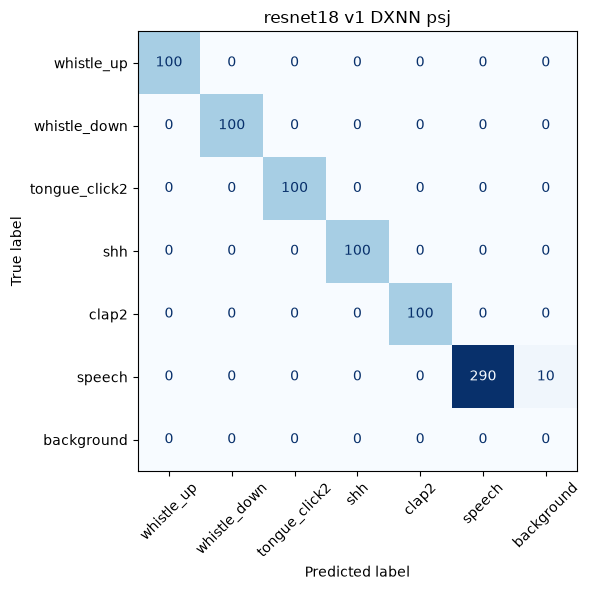

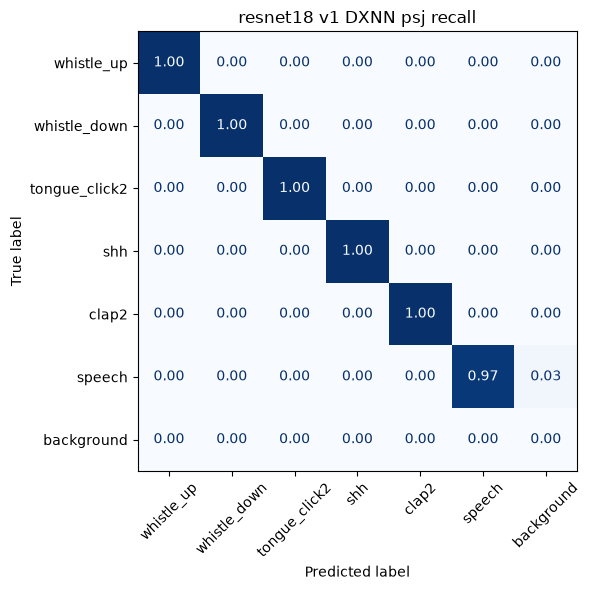

saved /home/kau-2024128055/kau-on-device-final/resnet18_v1/dxnn_test/confusion_test_psj.png
saved /home/kau-2024128055/kau-on-device-final/resnet18_v1/dxnn_test/confusion_test_psj_recall.png

===== jsh =====
               precision    recall  f1-score   support

   whistle_up      1.000     0.650     0.788        40
 whistle_down      0.931     0.643     0.761        42
tongue_click2      1.000     0.756     0.861        41
          shh      0.639     1.000     0.779        53
        clap2      0.467     0.350     0.400        60
       speech      1.000     0.841     0.913      1800
   background      0.000     0.000     0.000         0

     accuracy                          0.821      2036
    macro avg      0.719     0.606     0.643      2036
 weighted avg      0.973     0.821     0.888      2036



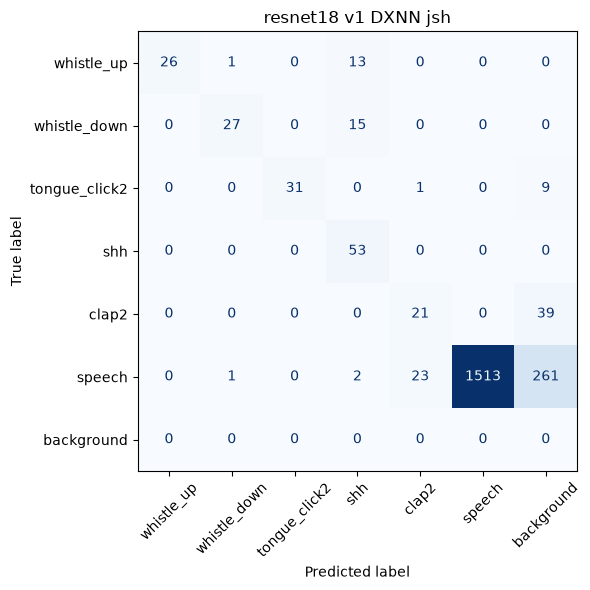

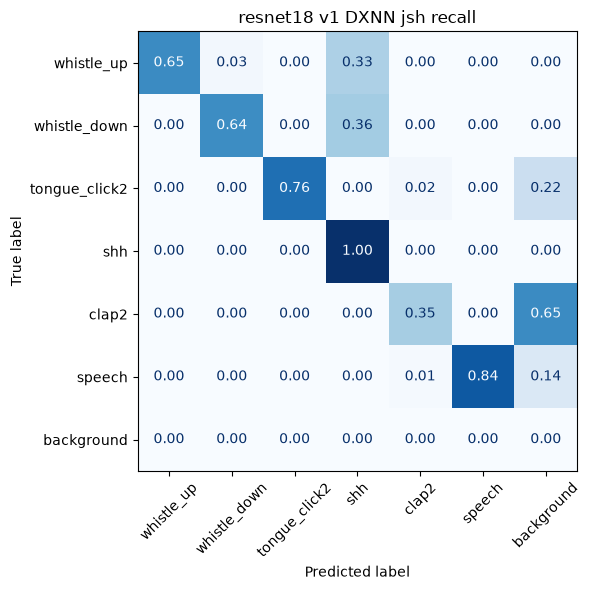

saved /home/kau-2024128055/kau-on-device-final/resnet18_v1/dxnn_test/confusion_test_jsh.png
saved /home/kau-2024128055/kau-on-device-final/resnet18_v1/dxnn_test/confusion_test_jsh_recall.png


In [12]:
results = {}
for name, folder in SETS.items():
    y_true, y_pred = evaluate(folder)
    results[name] = save_confusion(name, y_true, y_pred)

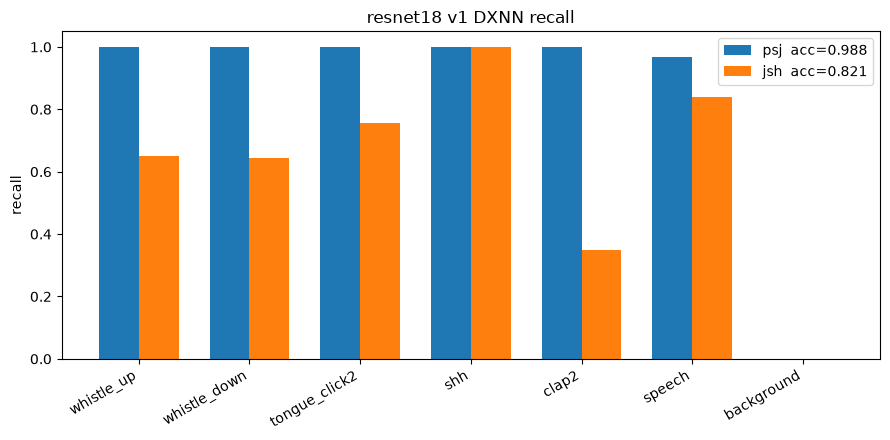

saved /home/kau-2024128055/kau-on-device-final/resnet18_v1/dxnn_test/recall_psj_jsh.png


In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(CLASSES))
width = 0.36
for i, name in enumerate(results):
    vals = [results[name]["recall"][c] for c in CLASSES]
    ax.bar(x + (i - 0.5) * width, vals, width, label=f"{name}  acc={results[name]['accuracy']:.3f}")
ax.set_xticks(x, CLASSES, rotation=30, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("recall")
ax.set_title("resnet18 v1 DXNN recall")
ax.legend()
fig.tight_layout()
bar_path = OUT / "recall_psj_jsh.png"
fig.savefig(bar_path, dpi=120)
plt.show()
print("saved", bar_path)